In [4]:
# -- Import Packages
#!/usr/bin/env python
%matplotlib inline  

#ipython magic to make wiphy module autoreload
%load_ext autoreload
%autoreload 2

#import packages
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import pandas as pd
import time
import scipy.integrate as spi
import os
from sklearn.metrics import auc 
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")


import seaborn as sns
from statannotations.Annotator import Annotator
from scipy.stats import mannwhitneyu



# -- load data for all infections
#full_data_file = r'/Users/kowens2/Library/CloudStorage/OneDrive-FredHutchinsonCancerResearchCenter/Monolix/NBA Cohort/Data/NBA_1510infections.csv'
#full_data_df = pd.read_csv(full_data_file)

# -- Functions
def GetParams(parameters_df, ID, style = 'mode'):
    ''' 
    input:
        - data frame with parameter values as columns, individuals as rows
        - ID identifying individual of interest
        - style = 'mode' or 'mean' or 'SAEM' depending on which parameter values are preferred
    return:
        - dictionary with parameter names as key and parameter values as values
    '''
    i = ID
    cols = list(parameters_df)
    pid_params = parameters_df[parameters_df.id == i].copy()
    values = []
    keys = []
    for c in cols:
        if style in c:
            k = c.split('_')[0]
            keys.append(k)
            v = pid_params[c].values[0]
            values.append(v)
        for i,(v,k) in enumerate(zip(values, keys)):
            if 'log10' in k:
                values[i] = 10**v
                keys[i] = k.split('0')[1]

    params = dict(zip(keys, values))
    return params

def Simulate(func, param_order, param_dict, init, tend, N):
    '''
    input: 
        - func is a function that takes in the state variable, time and parameters and returns the derivative
        - params is a dictionary of the parameter values 
        - init is a dictionary of the initial condition to simulate from 
    return: 
        - trajectory simulated from init for tspan using func with given params
    '''
    # make parameter list in correct order
    params = []
    for k in param_order:
        params.append(param_dict[k])
    # build tspan
    tspan = np.linspace(0,tend,N)
    # incorporate E0
    init[5] = param_dict['E0']
    # simulate using scipy integrate
    y = spi.odeint(func, init, tspan, args = tuple(params))
    return tspan,y

# Set up initial condition
T_0 = 10**7
Ie_0 = 0;
Ip_0 = 0;
R_0 = 0;
V_0 = 0.075;
E_0 = 0;

init = [T_0, Ie_0,Ip_0, R_0, V_0,E_0]

# Write function for model simulation
def deriv(y, t, beta, phi, eta,gamma, delta,k, p,c,theta,h,r):
    T,Ie,Ip,R,V,E = y
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R = phi*Ip*T -eta*R
    ddt_V = p*Ip-c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_V, ddt_E

param_order = ['beta', 'phi','eta','gamma', 
                         'delta','k','p','c','theta','h','r']

def derivBUB(y, t, beta, phi, eta,gamma, delta,k,  p,c,theta,h,r):
    T,Ie,Ip,R,V,E = y
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R =  phi*Ip*T -eta*R
    ddt_Vb = p*Ip - delta*Vb - rho*Vb
    ddt_V = rho*Vb-c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_V, ddt_E


def derivOseltamivir(y, t, beta, phi, eta,gamma, delta,k,p,c,theta,h,r, treat_start, treat_end, avg_efficacy):
    T,Ie,Ip,R,Vb,V,E = y
    
    if t > treat_start and t < treat_end:
        eps = avg_efficacy
    else:
        eps = 0
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R = phi*Ip*T - eta*R
    ddt_Vb = eps*p*Ip - (delta + k*E)*Vb
    ddt_V = (1-eps)*p*Ip - c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_Vb,ddt_V, ddt_E

def derivBaloxavir(y, t, beta, phi, eta,gamma, delta,k,  p,c,theta,h,r,treat_start, treat_end, avg_efficacy):
    T,Ie,Ip,R,Vb,V,E = y
    
    if t > treat_start and t < treat_end:
        eps = avg_efficacy
    else:
        eps = 0
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R = phi*Ip*T - eta*R
    ddt_Vb = 0
    ddt_V = (1-eps)*p*Ip - c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_Vb,ddt_V, ddt_E

param_order_treatment = ['beta', 'phi','eta','gamma', 
                         'delta','k','p','c','theta','h','r',
                         'treat_start', 'treat_end', 'avg_efficacy']

def SimulateTreatment(func, param_order, param_dict, init, tend, N, treat_start, treat_end, avg_efficacy):
    '''
    input: 
        - func is a function that takes in the state variable, time and parameters and returns the derivative
        - params is a dictionary of the parameter values 
        - init is a dictionary of the initial condition to simulate from 
    return: 
        - trajectory simulated from init for tspan using func with given params
    '''
    _
    # make parameter list in correct order
    params = []
    for k in param_order:
        params.append(param_dict[k])
    # add treatment parameters
    params.append(treat_start)
    params.append(treat_end)
    params.append(avg_efficacy)
    # build tspan
    tspan = np.linspace(0,tend,N)
    # incorporate E0
    init[6] = param_dict['E0']
    # simulate using scipy integrate
    y = spi.odeint(func, init, tspan, args = tuple(params))
    return tspan,y
    
Vb_0 = 0
initTreatment = [T_0, Ie_0,Ip_0, R_0, Vb_0, V_0, E_0]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
# Adjust the timing of enrollment/baseline measurement to align untreated trajectories with placebo group

# NEJM (approximated) time points of change from baseline in Phase 3 trial (Figure 3):
Placebo_timepoints = np.array([0,1,2,3,4,5,8])        # Day 0 = Day 1 before the initiation of the trial regimen in NEJM paper

# Approximated data
# Placebo_Mean = np.array([0,-1.3,-2.9,-3.2,-4.2,-4.9,-5])

# Digitized data
Placebo_Mean = np.array([0,-1.2,-2.9,-3.34,-4.47,-4.49,-4.88])

# Revert back to viral load
'''
"The mean (±SD) viral loads on day 1 (before the initiation of the trial regimen) 
were 5.79±1.87 and 5.56±1.89 log10 50% tissue-culture infective dose (TCID50) 
per milliliter in the baloxavir and placebo groups, respectively."

LOD = 0.7 TCID50 

'''
# Given NEJM data: mean viral load on day 1 (before the initiation of the trial regimen):
Placebo_Baseline = 5.56          # SD: +/- 1.89 
#balox_baseline = 5.79           # SD: +/- 1.87

Placebo_VL = Placebo_Baseline + Placebo_Mean 


print(Placebo_VL)

[5.56 4.36 2.66 2.22 1.09 1.07 0.68]


In [6]:
#parameters_df = pd.read_csv('/Users/kowens2/Library/CloudStorage/OneDrive-FredHutchinsonCancerResearchCenter/Influenza/estimatedIndividualParameters-Best.txt')
#data_df = pd.read_csv('FLU_ALL_un_censored.csv')

#################################
## Fixed c, beta, h parameters - Pre-run (Best fit) ##
#################################
M4a_shifted_Hill8_fixed_c_Owens = "~/OneDrive - Fred Hutch Cancer Center/IAV Data/Monolix/Truncated Fittings/Projects/Test Models/Shifted Bounds - M4a/M4a_shifted_Hill8_fixed_c_Owens/IndividualParameters"
file_path = os.path.join(M4a_shifted_Hill8_fixed_c_Owens, "estimatedIndividualParameters.txt")

#################################
## Fixed c, beta, h, r, and a-error parameter
#################################
#M4a_fixed_c_beta_a0_99_rpop = "~/OneDrive - Fred Hutch Cancer Center/IAV Data/Monolix/Truncated Fittings/Projects/Test Models/Shifted Bounds - M4a/Uncensored/Fixed Error a/M4a_shifted_Hill8_fixed_c_beta_a0.99_rpop/Assessment/Assessment_003/Assessment_003"
#file_path = os.path.join(M4a_fixed_c_beta_a0_99_rpop, "IndividualParameters/estimatedIndividualParameters.txt")

# parameters read in 
parameters_df = pd.read_csv(file_path, header = 0, sep = ",")

# volunteer observed vl data
data_df = pd.read_csv("~/OneDrive - Fred Hutch Cancer Center/IAV Data/Data_IAV Model/FLU_ALL_un_censored.csv")

IDs = data_df.ID.unique()
colorDict = {0:'cornflowerblue',1:'tab:red'}

print(IDs)
print(parameters_df)
print(data_df)

['4A' '12A' '18A' '30A' '33A' '48A' '52A' '61A' '67A' '71A' '77A' '14B-A'
 '16B-A' '18B-A' '21B-A' '28B-A' '49B-A' '53B-A' '60B-A' '65B-A' '66B-A'
 '4B-B' '12B-B' '15B-B' '19B-B' '207B-B' '213B-B' '304B-B' '312B-B'
 '317B-B' '327B-B' '329B-B' '331B-B' '336B-B' '337B-B' '342B-B' '344B-B'
 '350B-B' '53B-B' '55B-B' '62B-B' '65B-B' '70B-B' '73B-B']
        id  log10beta_SAEM  delta_SAEM  log10p_SAEM  c_SAEM  gamma_SAEM  \
0       4A        -5.64272     1.10239      1.36365      15     6.30362   
1      12A        -5.70133     1.08271      1.37004      15     6.31936   
2      18A        -5.65362     1.07810      1.37866      15     6.23022   
3      30A        -5.74632     1.09067      1.36463      15     6.19980   
4      33A        -5.76658     1.08912      1.36921      15     6.16949   
5      48A        -5.84871     1.09420      1.27998      15     5.14124   
6      52A        -5.76989     1.08815      1.35334      15     6.05355   
7      61A        -6.02193     1.08439      1.22964  

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

## Redefined function that incorporates the CORRECT PK model defined for balox and oselt

def simulate_treatment_potency_matrix(V_untreated_alligned, IDs, parameters_df,
                                     Baselines, t_original,
                                     potency_range = np.arange(0, 1.1, 0.05),
                                     days_to_analyze=[1, 2, 3, 4, 5]):
    """
    Simulate treatment effects across different potencies and calculate 
    viral load reduction at specific days
    
    Parameters:
    V_untreated: Untreated viral load matrix (M patients x N timepoints)
    IDs: individual volunteer IDs
    parameters_df: Dataframe with individual's parameters from Get_params function
    Baselines: list of baseline indices for each volunteers
    potency_range: Array of treatment potencies (0-1, where 1 = 100% effective instead of 99%)
    days_to_analyze: Days post-baseline to analyze; from Day 1 - 5
    
    Returns:
    results_dict: Dictionary with median reduction matrices for each day; 
    Change for Mean or Median drop from baseline across all volunteers for each arm, potency, and day
    """

    treat_start = 0                       # treatment starts at baseline measurement (peak viral load) at time 0
    treat_end_B = treat_start + 3.5       # Baloxavir: 3.5 days
    treat_end_O = treat_start + 5         # Oseltamivir: 5 days

    # Using the aligned time vector (starts at 0 = baseline) from previous code chunk 
    N_tpts = V_untreated_alligned.shape[1]
    t_aligned = np.linspace(0, 21, N_tpts)
   
    # Set up a vector for the treatment scenarios
    treatments = ['Placebo', 'Baloxavir', 'Oseltamivir']
    
    # Initialize results dictionary
    results_dict = {}

    # For loop through the days_to_analyze to store in 'results_dict'
    for day in days_to_analyze:
        results_dict[f'Day_{day}'] = pd.DataFrame(
            index = treatments, 
            columns=[f'{int(p*100)}%' for p in potency_range]
        )
    
    # For-loop through each day to analyze
    for day in days_to_analyze:
        day_idx = np.argmin(np.abs(t - (t_baseline + day)))

        #t_alligned = np.linspace(0, 21, len(V_untreated_alligned[0]))
        #day_idx = np.argmin(np.abs(t_alligned - day))
        
        # For-loop through each potency level
        for potency in potency_range:
            potency_str = f'{int(potency*100)}%'
            
            # Vectors to store the calculated reductions for each treatment
            placebo_reductions = []
            balox_reductions = []
            oselt_reductions = []
            
            # For-loop through each volunteer to simulate the vl drop from baseline each treatment 
            for count, ID in enumerate(IDs):

                # Use the previously defined function to get individual's parameters "Mode" results from MONOLIX
                params_dict = GetParams(parameters_df, ID, style = 'mode')
                
                # Placebo (untreated) using aligned data 
                baseline = V_untreated_alligned[count,0]                     # get baseline from aligned data (index 0) 
                placebo_vl = V_untreated_alligned[count, day_idx]            # get placebo viral load from aligned data
                placebo_reductions.append(baseline - placebo_vl)             # calculate change from baseline and store into defined vector 

                # Get individual baseline (peak time) for treatment simulations
                baseline_ind = Baselines[count]
                tpk = t_original[baseline_ind]

                # Treatment timing relative to each individual's peak vl
                treat_start_temp = tpk + 0    # Start at (individual) vl peak 
                treat_end_B_temp = tpk + 3.5  # Treatment timing for Baloxavir: 3.5 days 
                treat_end_O_temp = tpk + 5    # Treatment timing for Oseltamivir: 5 days 

                #################################################################
                ######## Simiulate Treatment using 'derivBaloxavir' model #######
                #################################################################
                # Baloxavir effect (strong early effect, then decay) with variable efficacy
                # Baloxavir inhibit viral production 
                #'derivBaloxavir' model: 
                #  ddt_T = -beta*T*V - phi*Ip*T + eta*R
                #  ddt_Ie = beta*T*V - gamma*Ie
                #  ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
                #  ddt_R = phi*Ip*T - eta*R
                #  ddt_Vb = 0                              <- no bounded virus for Baloxavir simulation!
                #  ddt_V = (1-eps)*p*Ip - c*V              <- Efficacy term affects virus production 
                #  ddt_E = theta*E*Ip**h/(Ip**h+r**h)

                # simulate treatment with variable potency 
                # (func, param_order, param_dict, init, tend, N, treat_start, treat_end, avg_efficacy)
                ttB, ytB = SimulateTreatment(derivBaloxavir, param_order, params_dict,
                                             initTreatment, 40, 10000,
                                             treat_start_temp, treat_end_B_temp, potency)

                # Get balox viral load at specific day (aligned to baseline)
                balox_idx = baseline_ind + day_idx
                if balox_idx < len(ytB):
                    balox_vl = np.log10(np.maximum(ytB[balox_idx, 4] + ytB[balox_idx, 5], 0.1))     # log-transformed
                    balox_reductions.append(baseline - balox_vl)

                
                #balox_vl = np.log10(np.maximum(ytB[day_idx, 4] + ytB[day_idx, 5], 0.1))   
                #balox_reductions.append(baseline - balox_vl)


                ###################################################################
                ######## Simiulate Treatment using 'derivOseltamivir' model #######
                ###################################################################
                # Oseltamivir effect with variable efficacy
                # Oseltamivir inhibits the release of progeny virions from infected host cells 
                # 'derivOseltamivir' model: 
                # ddt_T = -beta*T*V - phi*Ip*T + eta*R
                # ddt_Ie = beta*T*V - gamma*Ie
                # ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
                # ddt_R = phi*Ip*T - eta*R
                # ddt_Vb = eps*p*Ip - (delta + k*E)*Vb
                # ddt_V = (1-eps)*p*Ip - c*V
                # ddt_E = theta*E*Ip**h/(Ip**h+r**h)

                tt, yt = SimulateTreatment(derivOseltamivir, param_order, params_dict,
                                             initTreatment, 40, 10000,
                                             treat_start_temp, treat_end_O_temp, potency)

                # Get viral load at specific day (aligned to baseline)
                oselt_idx = baseline_ind + day_idx
                if oselt_idx < len(yt):
                    oselt_vl = np.log10(np.maximum(yt[oselt_idx, 4] + yt[oselt_idx, 5], 0.1))       # log-transformed
                    oselt_reductions.append(baseline - oselt_vl)
            
                #oselt_vl = np.log10(np.maximum(yt[day_idx, 4] + yt[day_idx, 5], 0.1))    # log-transformed
                #oselt_reductions.append(baseline - oselt_vl)
            
            # Store median reductions
            # Storing the day, the treatment, the potency, and the median drop for all volunteers at that day and potency
            #results_dict[f'Day_{day}'].loc['Placebo', potency_str] = np.median(placebo_reductions)
            #results_dict[f'Day_{day}'].loc['Baloxavir', potency_str] = np.median(balox_reductions)
            #results_dict[f'Day_{day}'].loc['Oseltamivir', potency_str] = np.median(oselt_reductions)

            # Storing the day, the treatment, the potency, and the MEAN drop for all volunteers at that day and potency
            results_dict[f'Day_{day}'].loc['Placebo', potency_str] = np.mean(placebo_reductions)
            results_dict[f'Day_{day}'].loc['Baloxavir', potency_str] = np.mean(balox_reductions)
            results_dict[f'Day_{day}'].loc['Oseltamivir', potency_str] = np.mean(oselt_reductions)
            
    return results_dict


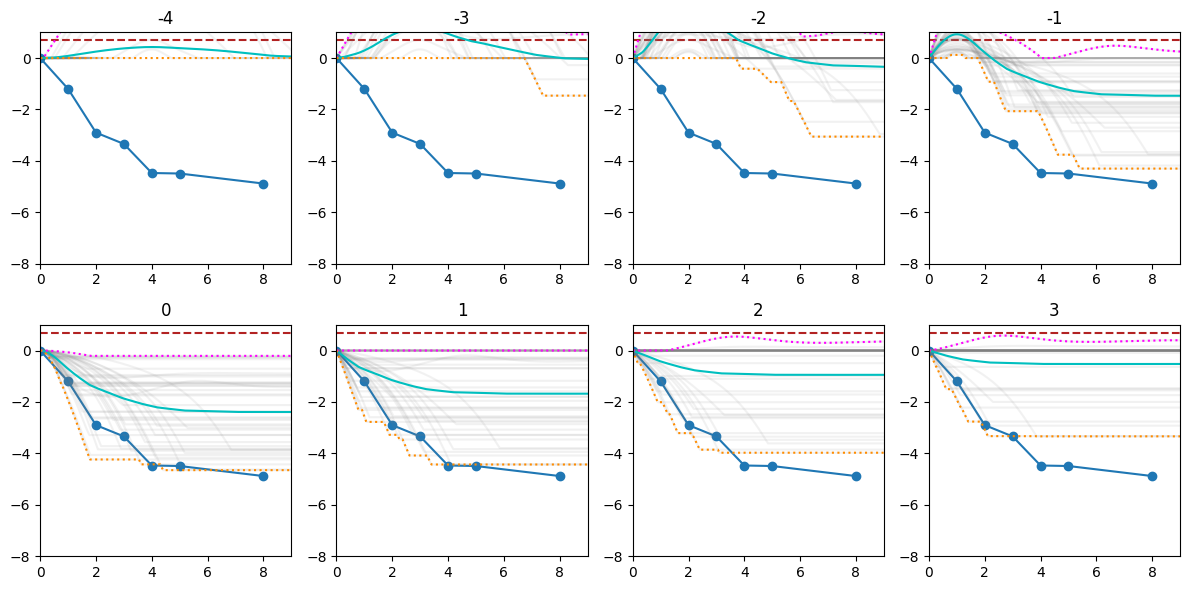

In [13]:
# Aligning the measure of drop from baseline based on peak viral load (of each individual) 
# Establish time vector t
for count,ID in enumerate(IDs[0:1]):
    params_dict = GetParams(parameters_df, ID, style = 'mode') 
    t,y = Simulate(deriv, param_order, params_dict, init, 40, 10000)

dt = t[1]-t[0]                    # delta time
ind_1day = np.round(1/dt)         # frequency of sampling: the number of time steps that equal 1 day 
                                  # (10,0000 points over 40 days = 10000/40 = 250 per day) 

fig, axs = plt.subplots(2,4, figsize = (12,6))
IDs = data_df.ID.unique()

N = len(t)                        # length of time
M = len(IDs)                      # length of volunteers (44) 

V_untreated = np.zeros((M,N))     # array for simulated values

for count,ID in enumerate(IDs):

    # get parameters function
    params_dict = GetParams(parameters_df, ID, style = 'mode') 

    # Simulate ODE system with individual's parameters
    t,y = Simulate(deriv, param_order, params_dict, init, 40, 10000)

    # maximum vl of individual retrieved from the fifth column; if the original value from y[:,4] is less than initial then convert to inital 10^0.7
    V = np.maximum(y[:,4], 10**0.7)
    
    #plt.plot(t-t_baseline,V,color ='tab:gray', alpha = 0.1, lw = 1)

    # store into matrix 
    V_untreated[count,:] = V

'''
# DOB: days from onset to baseline
# avg_DOB: the number of days relative to peak viral load the baseline measurement is taken (DOB: day of baseline)
# (-4, 4): the range from -4 to 3 days
# -4, -3, -2, -1: Days BEFORE peak viral load (early infection)
# 0: Day at peak viral load
# 1, 2, 3: Days after peak viral load (declining phase) 
'''

for avg_DOB, ax in zip(np.arange(-4,4),fig.axes):
    ax.plot(Placebo_timepoints,Placebo_Mean,'o-')

    # horizontal line: limit of detection = 0.7 
    ax.hlines(y = 0.7, xmin = 0, xmax = 10, color = 'firebrick',ls = '--')           

    # array to store the drop_untreated difference values
    Drop_untreated = np.zeros((M,N))

    for i in np.arange(0,M):
        # ind_pk: peak of each volunteer 
        ind_pk = np.argmax(V_untreated[i,:])          

        # ind_baseline: individual baseline calculated
        # find the array index corresponding to a specific time point that is the avg day of baseline away from peak viral load
        ind_baseline = int(ind_pk + ind_1day*avg_DOB)     

        # Baseline of individual volunteers
        baseline = V_untreated[i,ind_baseline]

        # Calculating the indivdiual drop: log10(ind drop) - 
        Drop_untreated[i, 0:len(V_untreated[i,ind_baseline:])] = np.log10(V_untreated[i,ind_baseline:])-np.log10(baseline)

        # plot the drop 
        ax.plot(t[0:len(V_untreated[i,ind_baseline:])],
                Drop_untreated[i, 0:len(V_untreated[i,ind_baseline:])],
                '-', color='tab:gray', alpha = 0.1) 
    
    # MEAN drop from baseline of untreated
    ax.plot(t,np.mean(Drop_untreated, axis = 0),'-', color='c')   

    # MAX drop from baseline of untreated
    ax.plot(t,np.max(Drop_untreated, axis = 0),':', color='fuchsia') 

    # MIN drop from baseline of untreated
    ax.plot(t,np.min(Drop_untreated, axis = 0),':', color='darkorange')  
    
    ax.set_xlim(0,9)
    ax.set_ylim(-8,1)
    ax.set_title(str(avg_DOB))
    
plt.tight_layout()

Text(0.5, 1.0, 'Mean Mechanisms of Action on Viral Clearance Kinetics')

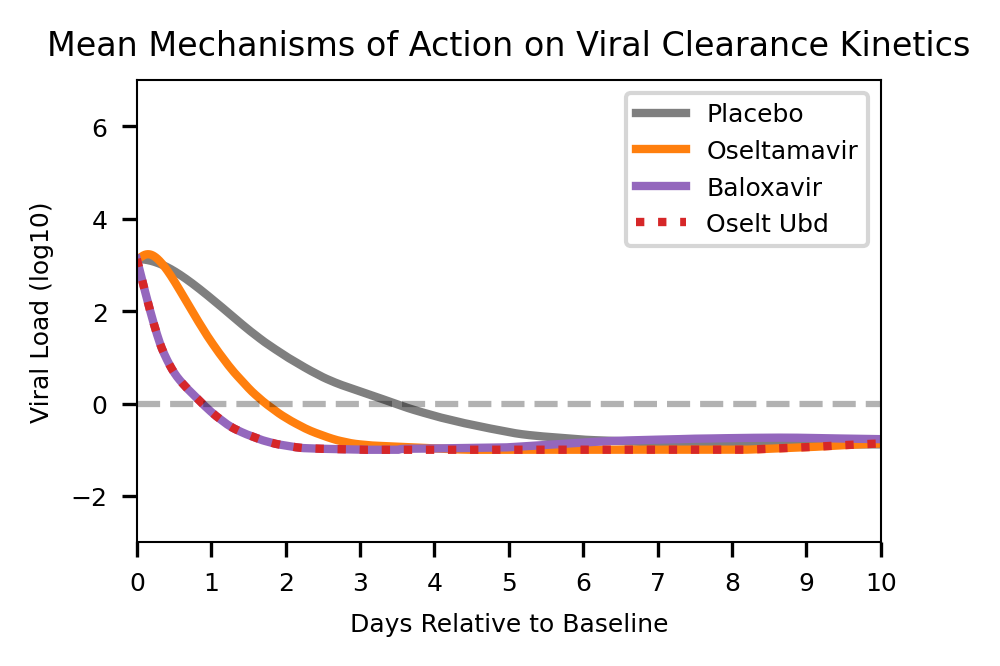

In [14]:
## Plotting the viral load change relative to baseline 

IDs = data_df.ID.unique()

t_baseline = 0                            # time of baseline measurement is at peak viral load
treat_start = 0                           # start treatment immediately following baseline measurement
treat_end_B =  treat_start + 3.5          # 3.5 days of baloxavir
treat_end_O =  treat_start + 5            # 5 days of oseltamavir
avg_efficacy = .99 # high avg efficacy

fig = plt.figure(figsize =(3.2,2), dpi = 300)
plt.rcParams.update({'font.size': 6, 'axes.linewidth':.5})

N = len(t)
M = len(IDs)

# Arrays to store values
V_untreated = np.zeros((M,N))
V_O = np.zeros((M,N))
V_OUB = np.zeros((M,N))
V_B = np.zeros((M,N))

# Vector to store baseline values
Baselines = []

for count,ID in enumerate(IDs):
    params_dict = GetParams(parameters_df, ID, style = 'mode')

    ################################################################
    ####### Simulating the ODE system (Model 4) #######
    t,y = Simulate(deriv, param_order, params_dict, init, 40, 10000)
    V = np.log10(np.maximum(y[:,4],0.1))
    V_untreated[count,:] = V
    
    ################################################################
    ######## Determine individual peak viral load ########
    pk_ind = np.argmax(V)          # peak viral load
    tpk = t[np.argmax(V)]          # time of peak viral load 
    Baselines.append(pk_ind)       # append to 'Baselines' vector 
    
    # set individual timing
    t_baseline_temp = tpk + t_baseline

    ################################################################
    ######## Plotting ########
    ####### Placebo Individual's baseline drop in gray
    #plt.plot(t-t_baseline_temp,V,color ='tab:gray', alpha = 0.1, lw = 1)
    
    treat_start_temp = tpk + treat_start             # start of treatment for placebo at peak viral + '0' days
    treat_end_B_temp = tpk + treat_end_B             # start of treatment for balox
    treat_end_O_temp = tpk + treat_end_O             # start of treatment for oselt

    ####################################################################
    ####### Simulating the treatment system (Model 4 with oselt) #######
    ####################################################################
    # oseltamivir: V0 - oselt, VUB - unbounded
    tt,yt = SimulateTreatment(derivOseltamivir, param_order, params_dict, 
                                initTreatment, 40, 10000,
                                treat_start_temp, treat_end_O_temp, avg_efficacy)

    ####### Oselt all individual's baseline drop in orange
    VO = np.log10(np.maximum(yt[:,4]+yt[:,5],0.1))                                      
    V_O[count,:] = VO
    # plt.plot(t-t_baseline_temp,VO,color ='tab:orange', alpha = 0.1, lw = 1)

    ####### Oselt unbounded virus: all individual's baseline drop in red
    VUB = np.log10(np.maximum(yt[:,5],0.1))           
    V_OUB[count,:] = VUB
    #plt.plot(t-t_baseline_temp,VUB,color ='tab:red', alpha = 0.1, lw = 1)

    #####################################################################
    ##### Simulating the treatment system (Model 4 with baloxavir) ######
    ####################################################################
    # baloxavir
    ttB,ytB = SimulateTreatment(derivBaloxavir, param_order, params_dict, 
                                initTreatment, 40, 10000, 
                                treat_start_temp, treat_end_B_temp, avg_efficacy)
    
    ####### Balox all individual's baseline drop in purple
    VB = np.log10(np.maximum(ytB[:,4]+ytB[:,5],0.1))
    V_B[count,:] = VB
    #plt.plot(t-t_baseline_temp,VB,color ='tab:purple', alpha = 0.1, lw = 1)
    

####################################################################
# Okay we need to align things by the individual baseline
N_tpts = 5250 # 3 weeks (21 days)
V_untreated_alligned = np.zeros((M,N_tpts))
V_B_alligned = np.zeros((M,N_tpts))        #balox
V_O_alligned = np.zeros((M,N_tpts))        #oselt
V_OUB_alligned = np.zeros((M,N_tpts))      #oselt unbded

####################################################################
## Calculating the individual's drop from baselines
for i in np.arange(0,M):
    baseline_ind = Baselines[i]
    V_untreated_alligned[i,:] = V_untreated[i,baseline_ind:baseline_ind+N_tpts]
    V_B_alligned[i,:] = V_B[i,baseline_ind:baseline_ind+N_tpts]
    V_O_alligned[i,:] = V_O[i,baseline_ind:baseline_ind+N_tpts]
    V_OUB_alligned[i,:] = V_OUB[i,baseline_ind:baseline_ind+N_tpts]

####################################################################
## Plotting the mean of the three treatment arms
## Note that the unbounded virus for oseltamivir arm (dashed line) should be the same as baloxavir 
## due to the same mechanism of action modeled by the ODE systems 
plt.plot(np.linspace(0,21,N_tpts), np.mean(V_untreated_alligned, axis = 0), color = 'tab:gray', lw = 2, label = 'Placebo')
plt.plot(np.linspace(0,21,N_tpts), np.mean(V_O_alligned, axis = 0), color = 'tab:orange', lw = 2, label = 'Oseltamavir')
plt.plot(np.linspace(0,21,N_tpts), np.mean(V_B_alligned, axis = 0), color = 'tab:purple', lw = 2, label = 'Baloxavir')
plt.plot(np.linspace(0,21,N_tpts), np.mean(V_OUB_alligned, axis = 0), color = 'tab:red', lw = 2, ls = ":", label = 'Oselt Ubd')


####################################################################
## Set plot characteristics
plt.xlim(0,10)
plt.ylim(-3,7)
plt.xticks(np.arange(0,11))
plt.xlabel('Days Relative to Baseline')
plt.ylabel('Viral Load (log10)')
plt.hlines(y = 0, xmin = 0, xmax = 10,alpha = 0.3, color ='k', ls = '--')
plt.legend(loc = "upper right")          # Display the legend
plt.title('Mean Mechanisms of Action on Viral Clearance Kinetics', fontsize=8) 


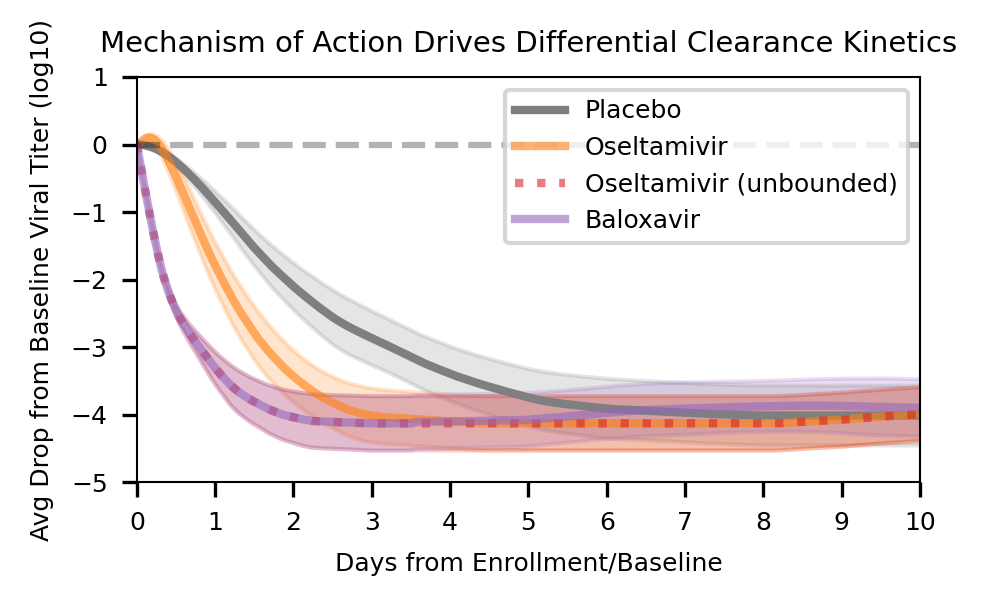

In [91]:
## RIBBON PLOTS ##
## Plotting drop from baseline with 95% CI 

DropBaseline_untreated = np.zeros((M,N_tpts))
DropBaseline_O = np.zeros((M,N_tpts))
DropBaseline_OUB = np.zeros((M,N_tpts))
DropBaseline_B = np.zeros((M,N_tpts))

###############################################################
for count in np.arange(0,M):
    
    # Determine baseline value first
    baseline = V_untreated_alligned[count, 0]

    #### Calculate the differences for each arm
    # Placebo
    DropBaseline_untreated[count, :] = V_untreated_alligned[count, :] - baseline

    # Oseltamivir 
    DropBaseline_O[count, :] = V_O_alligned[count, :] - baseline

    # Baloxavir
    DropBaseline_B[count, :] = V_B_alligned[count, :] - baseline

    # Unbounded oseltamivir 
    DropBaseline_OUB[count, :] = V_OUB_alligned[count, :] - baseline

###############################################################
fig = plt.figure(figsize =(3.2, 2), dpi = 300)
plt.rcParams.update({'font.size': 6, 'axes.linewidth':.5})

###############################################################
# All Indivdiuals 
###############################################################
#plt.plot(np.linspace(0,21,N_tpts), DropBaseline_untreated.T, color = 'tab:gray',alpha = 0.1, lw = .5 );
#plt.plot(np.linspace(0,21,N_tpts), DropBaseline_O.T, color = 'tab:orange',alpha = 0.1, lw = .5  );
#plt.plot(np.linspace(0,21,N_tpts), DropBaseline_B.T,  color = 'tab:purple',alpha = 0.1 , lw = .5 );
###############################################################


###############################################################
# drop from baseline for placebo (gray)
###############################################################
# Mean
plt.plot(np.linspace(0,21,N_tpts), np.mean(DropBaseline_untreated, axis = 0), color = 'tab:gray', lw = 2, label = 'Placebo')

interval = 0.95
CI_low = []
CI_high = []
for i in np.arange(0,N_tpts-1):
    filtered_data = DropBaseline_untreated[:,i]
    ans = st.norm.interval(confidence = interval, loc = np.mean(filtered_data), scale=st.sem(filtered_data))
    CI_low.append(ans[0])
    CI_high.append(ans[1]) 

CI_low.append(ans[0])
CI_high.append(ans[1]) 
plt.fill_between(np.linspace(0,21,N_tpts), CI_low, CI_high,color = 'tab:gray',alpha = .2)

###############################################################
# drop from baseline for OSELTAMIVIR (orange)
###############################################################
# Mean
plt.plot(np.linspace(0,21,N_tpts), np.mean(DropBaseline_O, axis = 0), 
         alpha = 0.6,
         color = 'tab:orange', 
         lw = 2, 
         label = 'Oseltamivir')
CI_low = []
CI_high = []

for i in np.arange(0,N_tpts-1):
    filtered_data = DropBaseline_O[:,i]
    ans = st.norm.interval(confidence = interval, loc=np.mean(filtered_data), scale=st.sem(filtered_data))
    CI_low.append(ans[0])
    CI_high.append(ans[1]) 

CI_low.append(ans[0])
CI_high.append(ans[1]) 
plt.fill_between(np.linspace(0,21,N_tpts), CI_low, CI_high,color = 'tab:orange',alpha = .2)

###############################################################
# drop for UNBOUNDED oselt (red) 
###############################################################
# Mean 
plt.plot(np.linspace(0,21,N_tpts), np.mean(DropBaseline_OUB, axis = 0), 
         alpha = 0.6, 
         #linestyle =":", 
         color = 'tab:red', 
         lw = 2, 
         ls = ':',
         label = 'Oseltamivir (unbounded)')
CI_low = []
CI_high = []

for i in np.arange(0,N_tpts-1):
    filtered_data = DropBaseline_OUB[:,i]
    ans = st.norm.interval(confidence = interval, loc=np.mean(filtered_data), scale=st.sem(filtered_data))
    CI_low.append(ans[0])
    CI_high.append(ans[1]) 

CI_low.append(ans[0])
CI_high.append(ans[1]) 
plt.fill_between(np.linspace(0,21,N_tpts), CI_low, CI_high,color = 'tab:red',alpha = .2)

###############################################################
# drop for BALOXAVIR (purple) 
###############################################################
plt.plot(np.linspace(0,21,N_tpts), np.mean(DropBaseline_B, axis = 0), 
         alpha = 0.6,
         color = 'tab:purple', 
         lw = 2,
         label = 'Baloxavir')
CI_low = []
CI_high = []

for i in np.arange(0,N_tpts-1):
    filtered_data = DropBaseline_B[:,i]
    ans = st.norm.interval(confidence =interval, loc=np.mean(filtered_data), scale=st.sem(filtered_data))
    CI_low.append(ans[0])
    CI_high.append(ans[1]) 

CI_low.append(ans[0])
CI_high.append(ans[1]) 
plt.fill_between(np.linspace(0,21,N_tpts), CI_low, CI_high,color = 'tab:purple',alpha = .2)


###############################################################
# Set plot properties
###############################################################
plt.hlines(y = 0, xmin = 0, xmax = 10, alpha = 0.3, ls = '--', color = 'k')
plt.xlim(0,10)
plt.xticks(np.arange(0,11))
plt.yticks(np.arange(-8,2))
plt.ylim(-5,1)

ax = plt.gca()
ax.spines[['right', 'top']].set_visible(True)
plt.legend()
plt.ylabel('Avg Drop from Baseline Viral Titer (log10)')
plt.xlabel('Days from Enrollment/Baseline')                # original x-label: days from baseline = peak viral load
#plt.xlabel('Days from Peak Viral Titer')
plt.title('Mechanism of Action Drives Differential Clearance Kinetics', fontsize = 7 )


plt.tight_layout()
plt.savefig('AvgBehavior.png',bbox_inches='tight', transparent = True)

In [26]:
# Print the simulated results for each day of each treatment arm  
day1_results = results['Day_1']

##### Extract and format Day 1-3 results #####
day1_results = results['Day_1'].astype(float)
day2_results = results['Day_2'].astype(float)
day3_results = results['Day_3'].astype(float)


##### Printing the table for Day 1 Results #####
print("\n" + "="*80)
print("DAY 1 DROP FROM BASELINE RESULTS (log10 VL reduction)")
print("="*80)
print(f"{'Treatment':<15}", end='')
for col in day1_results.columns:
    print(f"{col:>10}", end='')
print()
print("-"*100)

for treatment in day1_results.index:
    print(f"{treatment:<15}", end='')
    for potency in day1_results.columns:
        value = day1_results.loc[treatment, potency]
        print(f"{value:>10.2f}", end='')
    print()
print("="*100)


##### Printing the table for Day 2 Results #####
print("\n" + "="*80)
print("DAY 2 DROP FROM BASELINE RESULTS (log10 VL reduction)")
print("="*80)
print(f"{'Treatment':<15}", end='')
for col in day2_results.columns:
    print(f"{col:>10}", end='')
print()
print("-"*100)

for treatment in day2_results.index:
    print(f"{treatment:<15}", end='')
    for potency in day2_results.columns:
        value = day2_results.loc[treatment, potency]
        print(f"{value:>10.2f}", end='')
    print()
print("="*100)

##### Printing the table for Day 3 Results #####
print("\n" + "="*80)
print("DAY 3 DROP FROM BASELINE RESULTS (log10 VL reduction)")
print("="*80)
print(f"{'Treatment':<15}", end='')
for col in day3_results.columns:
    print(f"{col:>10}", end='')
print()
print("-"*100)

for treatment in day3_results.index:
    print(f"{treatment:<15}", end='')
    for potency in day3_results.columns:
        value = day3_results.loc[treatment, potency]
        print(f"{value:>10.2f}", end='')
    print()
print("="*100)



DAY 1 DROP FROM BASELINE RESULTS (log10 VL reduction)
Treatment              0%        5%       10%       15%       20%       25%       30%       35%       40%       45%       50%       55%       60%       65%       70%       75%       80%       85%       90%       95%      100%
----------------------------------------------------------------------------------------------------
Placebo              0.85      0.85      0.85      0.85      0.85      0.85      0.85      0.85      0.85      0.85      0.85      0.85      0.85      0.85      0.85      0.85      0.85      0.85      0.85      0.85      0.85
Baloxavir            0.85      0.91      0.97      1.02      1.09      1.15      1.22      1.29      1.37      1.45      1.54      1.63      1.73      1.84      1.96      2.08      2.22      2.38      2.58      2.84      4.13
Oseltamivir          0.85      0.88      0.90      0.93      0.96      0.99      1.03      1.07      1.11      1.15      1.20      1.24      1.29      1.34      1.40 

In [27]:
# Transposing the x,y-axes 

def potency_vs_days_heatmap_from_results(results_dict, days_to_plot=[0, 1, 2, 3], figsize=(12, 4)):
    """
    Create separate heatmaps for each treatment with:
    - Y-axis: Potency levels
    - X-axis: Days post-baseline
    
    Parameters:
    results_dict: Dictionary from simulate_treatment_potency_matrix (above)
    days_to_plot: Which days to include (e.g., [0, 1, 2, 3])
    figsize: Figure size for each treatment
    
    Returns:
    figures: Dictionary with figure for each treatment
    """

    # Define vector for treatments
    treatments = ['Placebo', 'Baloxavir', 'Oseltamivir']
    
    # Custom colormaps for each treatment
    cmaps = {
        'Placebo': 'Blues',
        'Baloxavir': 'Purples',
        'Oseltamivir': 'Oranges'
    }
    
    figures = {}
    
    for treatment in treatments:
        
        # Get potency levels from first day
        first_day_key = f'Day_{days_to_plot[0]}'
        if first_day_key not in results_dict:
            print(f"Warning: {first_day_key} not found in results")
            continue
            
        # potency_levels = results_dict[first_day_key].columns.tolist()
        potency_levels = np.arange(0, 1.05, 0.05)
        
        # Build data matrix: rows = potencies, columns = days
        data_matrix = []
        
        for potency in potency_levels:
            row = []
            for day in days_to_plot:
                day_key = f'Day_{day}'
                if day_key in results_dict:
                    value = results_dict[day_key].loc[treatment, potency]
                    row.append(float(value))
                else:
                    row.append(np.nan)
            data_matrix.append(row)
        
        # Create DataFrame with correct orientation
        df = pd.DataFrame(
            data_matrix,
            index=potency_levels,  # Y-axis: potencies
            columns=[f'Day {d}' for d in days_to_plot]  # X-axis: days
        )
        
        # Calculate vmin/vmax for this treatment
        vmin = df.min().min()
        vmax = df.max().max()
        
        # Create figure
        fig, ax = plt.subplots(1, 1, figsize=figsize)
        
        # Create heatmap
        sns.heatmap(df, 
                   annot = True, 
                   fmt = '.2f',
                   cmap = cmaps[treatment],
                   vmin = vmin,
                   vmax = vmax,
                   ax = ax,
                   cbar_kws = {'label': 'Mean VL Reduction (log10)',
                              'labelsize': 16                       # colorbar tick labels font size     
                              },
                   annot_kws = {'fontsize': 14, 'fontweight': 'bold'},
                   linewidths = 0.5,
                   linecolor = 'white')

        # x-axis should Days post viral load (or drop from baseline)
        ax.set_xlabel('Days Post-Baseline', fontsize=13, fontweight='bold')

        # y-axis should varying efficacy rates
        ax.set_ylabel('Treatment Potency', fontsize=13, fontweight='bold')
        ax.set_title(f'{treatment} Treatment Effect Over Time', 
                    fontsize=15, fontweight='bold', pad=15)
        
        # Format axis labels
        ax.tick_params(axis='y', rotation=0)
        ax.tick_params(axis='x', rotation=0)
        
        plt.tight_layout()
        
        figures[treatment] = fig
    
    return figures

In [19]:
##########################################################
# Updating Figure with the following modifications:
# Use rainbow /multicolor heatmap for better readability
# Interchange x,y-axes
# set y-axis: potency for epsilon
# set x-axis: Days post baseline (Day 1 - Day 3) 
##########################################################

# Updated: Using the updated simulate_treatment_potency_matrix function defined above, we run the usage here with the
# aligned individual data interchanging x,y-axes

def updated_potency_analysis(V_untreated_alligned, IDs, parameters_df, Baselines, t_original):
    """
    Parameters:
    V_untreated_alligned: Aligned untreated viral load matrix
    IDs: Volunteer IDs (n = 44)
    parameters_df: Parameter dataframe
    Baselines: List of baseline indices for each volunteer
    t_original: original time vector 
    """

    # Define potency range (0% to 100% in 5% increments)
    potency_range = np.arange(0, 1.05, 0.05)
    days_to_analyze = [0, 1, 2, 3, 4, 5, 6]           # Focusing on Days 0 - 3; including day 0 (peak vl?)
    

    # Generate results using simulated treatment matrix function
    results = simulate_treatment_potency_matrix(V_untreated_alligned, 
                                                IDs, 
                                                parameters_df, 
                                                Baselines, 
                                                t_original,
                                                potency_range = potency_range,
                                                days_to_analyze = days_to_analyze
    )

    # Transpose the x,y-axes: Create potency vs days heatmaps (separate for each treatment); instead of days vs potency
    figs_potency_vs_days = potency_vs_days_heatmap_from_results(
        results, 
        days_to_plot=[0, 1, 2, 3]
     )
    
    
    # Print summary
    print("\nSample Results (Day 1, 50% Potency):")
    print("="*40)
    if 'Day_1' in results and '50%' in results['Day_1'].columns:
        day1_50 = results['Day_1']['50%']
        for treatment in day1_50.index:
            print(f"{treatment}: {day1_50[treatment]:.2f} log10 reduction")
    
    return results, figs_potency_vs_days


In [28]:
def placebo_only_heatmap(results_dict, days_to_plot=[0, 1, 2, 3], figsize=(10, 5)):
    """
    Create heatmap for PLACEBO ONLY
    Y-axis: Potency, X-axis: Days
    """
    import seaborn as sns

    
    # Get potency levels
    first_day_key = f'Day_{days_to_plot[0]}'
    potency_levels = results_dict[first_day_key].columns.tolist()
    #potency_range = np.arange(0, 1.05, 0.05)
    
    # Build data matrix for balox
    balox_data_matrix = []
    
    for potency in potency_levels:
        row = []
        for day in days_to_plot:
            day_key = f'Day_{day}'
            if day_key in results_dict:
                value = results_dict[day_key].loc['Placebo', potency]
                row.append(float(value))
            else:
                row.append(np.nan)
        balox_data_matrix.append(row)
    
    # Create DataFrame
    df = pd.DataFrame(
        balox_data_matrix,
        index = potency_levels,
        columns = [f'Day {d}' for d in days_to_plot]
    )
    
    # Create figure
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    
    # Create heatmap
    sns.heatmap(df, 
                #annot = True, 
                fmt = '.2f',
                cmap = 'coolwarm',
                #vmin = vmin,
                #vmax = vmax,
                ax = ax,
                #cbar_kws = {'label': 'Mean VL Reduction (log10)'},               
                #annot_kws = {'fontsize': 14, 'fontweight': 'bold'}, 
                linewidths = 0.5,
                linecolor = 'white')

    # SET COLORBAR FONT SIZES AFTER CREATION
    cbar = ax.collections[0].colorbar
    cbar.set_label('Mean VL Reduction (Log10)', 
                  fontsize = 16,           # Colorbar label font size
                  fontweight = 'bold')
    cbar.ax.tick_params(labelsize  = 14)   # Colorbar tick numbers font size
    ax.invert_yaxis()
    
    ax.set_xlabel('Days Post-Baseline', fontsize = 16, fontweight='bold')
    ax.set_ylabel('Treatment Potency', fontsize = 16, fontweight='bold')
    ax.set_title('Placebo: Mean Viral Load Change Over Time',                                # Change plot title for each treatment
                fontsize=16, fontweight = 'bold', pad=15)
    
    ax.tick_params(axis = 'y', rotation = 25, labelsize = 12)
    ax.tick_params(axis = 'x', rotation = 0, labelsize = 12)
    
    plt.tight_layout()
    
    return fig

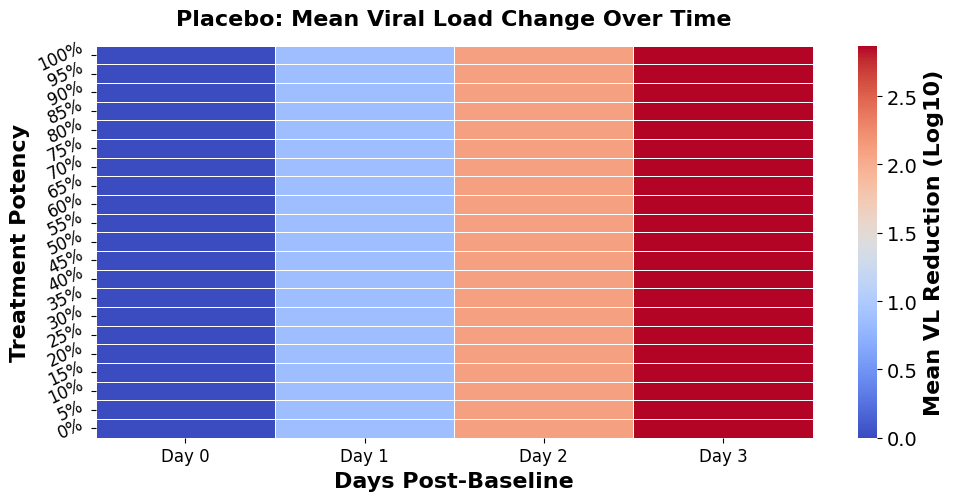

In [92]:
# Run the above functions to create heatmap for Placebo Treated Only 
#results, _ = updated_potency_analysis(V_untreated_alligned, IDs, parameters_df, Baselines, t)
placebo_fig = placebo_only_heatmap(results, days_to_plot = [0, 1, 2, 3])

# Save the figures (separately for each treatment) 
#placebo_fig.savefig('Placebo_Only_Heatmap.png', bbox_inches='tight', dpi=300)
plt.show()

In [165]:
## Heatmap for Baloxavir simulation only 
## Y-axis: potency
## X-axis: Days post baseline
    
def balox_only_heatmap(results_dict, days_to_plot=[0, 1, 2, 3], figsize=(2, 4)): ##size(width, height)
    """
    Create heatmap for Baloxavir ONLY
    Y-axis: Potency, X-axis: Days
    """
    
    # Get potency levels
    first_day_key = f'Day_{days_to_plot[0]}'
    potency_levels = results_dict[first_day_key].columns.tolist()
    
    # Build data matrix for Placebo
    data_matrix = []
    for potency in potency_levels:
        row = []
        for day in days_to_plot:
            day_key = f'Day_{day}'
            if day_key in results_dict:
                value = results_dict[day_key].loc['Baloxavir', potency]
                row.append(float(value))
            else:
                row.append(np.nan)
        data_matrix.append(row)
    
    # Create DataFrame
    df = pd.DataFrame(
        data_matrix,
        index = potency_levels,
        columns = [f'Day {d}' for d in days_to_plot]
    )
    
    # Create figure
    #fig, ax = plt.subplots(1, 1, figsize=(width, height))
    fig, ax = plt.subplots(1, 1, figsize=(2, 4))
    
    # Create heatmap
    sns.heatmap(df, 
               #annot = False, 
               fmt = '.2f',
               cmap = 'coolwarm',
                #'Purples',
               ax = ax,
               cbar = False,
               #cbar_kws = {'label': 'Mean VL Reduction (log10)'},               
               #annot_kws = {'fontsi ze': 14, 'fontweight': 'bold'}
               #linewidths = 0.5,
               #linecolor='white'
               )

    # SET COLORBAR FONT SIZES AFTER CREATION
    #cbar = ax.collections[0].colorbar
    #cbar.set_label('Mean VL Reduction (Log10)', 
    #              fontsize = 16,           # Colorbar label font size
    #              fontweight = 'bold')
    #cbar.ax.tick_params(labelsize  = 14)   # Colorbar tick numbers font size
    #ax.invert_yaxis()                      # invert y-axis: efficacy rates
    ax.set_xlabel('Days Post-Baseline', fontsize = 10, fontweight='bold')
    ax.set_ylabel('Treatment Potency', fontsize = 10, fontweight='bold')

    
    # Change plot title for each treatment
    ax.set_title('Baloxavir', fontsize = 12, fontweight='bold', pad = 15)
    
                
    
    ax.tick_params(axis = 'y', rotation = 15, labelsize = 8)
    ax.tick_params(axis = 'x', rotation = 25, labelsize = 8)
    
    plt.tight_layout()

    return fig

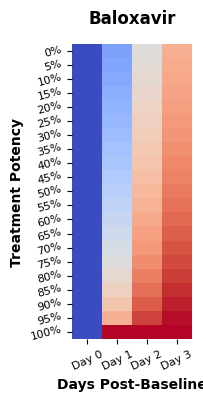

In [166]:

balox_fig = balox_only_heatmap(results, days_to_plot = [0, 1, 2, 3])
# Save the figures (separately for each treatment) 
fig_path = "/Users/angela.tower/Library/CloudStorage/OneDrive-WashingtonStateUniversity(email.wsu.edu)/Research/Influenza/Manuscript/Figures/"
balox_fig.savefig(fig_path+'Balox_Only_Heatmap2.png', bbox_inches = 'tight', transparent = True, dpi=300)
plt.show()

In [169]:
## Heatmap for Oseltamivir simulation only 
## Y-axis: potency
## X-axis: Days post baseline
    
def oselt_only_heatmap(results_dict, days_to_plot=[0, 1, 2, 3], figsize=(2.25, 4)):
    """
    Create heatmap for Oseltamivir ONLY
    Y-axis: Potency, X-axis: Days
    """
    
    # Get potency levels
    first_day_key = f'Day_{days_to_plot[0]}'
    potency_levels = results_dict[first_day_key].columns.tolist()
    
    # Build data matrix for Placebo
    data_matrix = []
    for potency in potency_levels:
        row = []
        for day in days_to_plot:
            day_key = f'Day_{day}'
            if day_key in results_dict:
                value = results_dict[day_key].loc['Oseltamivir', potency]
                row.append(float(value))
            else:
                row.append(np.nan)
        data_matrix.append(row)
    
    # Create DataFrame
    df = pd.DataFrame(
        data_matrix,
        index = potency_levels,
        columns = [f'Day {d}' for d in days_to_plot]
    )
    
    # Create figure
    fig, ax = plt.subplots(1, 1, figsize = (2.25, 4))
    
    # Create heatmap
    sns.heatmap(df, 
               #annot = True, 
               fmt = '.2f',
               cmap = 'coolwarm',
                #'Oranges',
               ax = ax,
               cbar_kws = {'label': 'Mean VL Reduction (log10)'},               
               annot_kws = {'fontsize': 14, 'fontweight': 'bold'}
               #linewidths = 0.5
               #linecolor = 'white'
               )
                

     # SET COLORBAR FONT SIZES AFTER CREATION
    cbar = ax.collections[0].colorbar
    cbar.set_label('Mean VL Reduction (Log10)', 
                  fontsize = 8,           # Colorbar label font size
                  fontweight = 'bold')
    cbar.ax.tick_params(labelsize  = 12)   # Colorbar tick numbers font size

    
    ax.set_xlabel('Days Post-Baseline', fontsize = 10, fontweight='bold')
    #ax.set_ylabel('Treatment Potency', fontsize = 10, fontweight='bold')
    # Change plot title for each treatment
    ax.set_title('Oseltamivir', fontsize=12, fontweight='bold', pad=15)
    #ax.invert_yaxis()
    ax.tick_params(axis = 'y', rotation = 15, labelsize = 8)
    ax.tick_params(axis = 'x', rotation = 25, labelsize = 8)
    
    plt.tight_layout()
    
    return fig


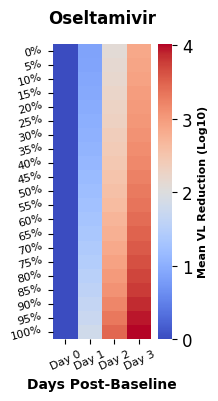

In [170]:

oselt_fig = oselt_only_heatmap(results, days_to_plot = [0, 1, 2, 3])
# Save the figures (separately for each treatment) 
fig_path = "/Users/angela.tower/Library/CloudStorage/OneDrive-WashingtonStateUniversity(email.wsu.edu)/Research/Influenza/Manuscript/Figures/"
oselt_fig.savefig(fig_path+'Oselt_Only_Heatmap2.png', bbox_inches='tight', transparent = True, dpi=300)
plt.show()
